In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

data = fetch_california_housing(as_frame=True)

df = pd.concat(
    [data.data, data.target.rename("HousePrice")],
    axis=1
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HousePrice
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   HousePrice  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
HousePrice    0
dtype: int64

Duplicate rows: 0

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HousePrice
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


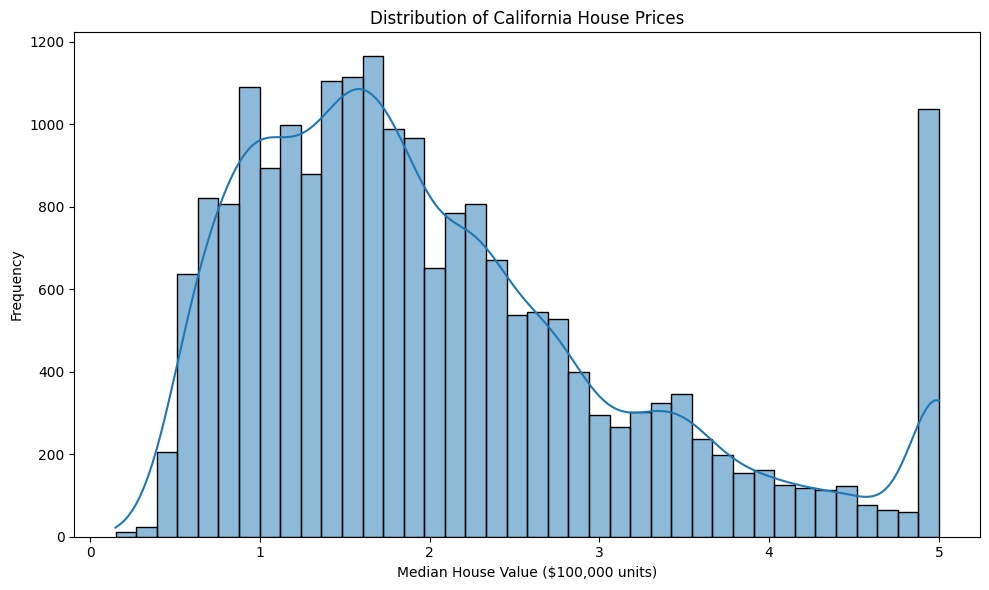

In [4]:

plt.figure(figsize=(10, 6))
sns.histplot(df["HousePrice"], bins=40, kde=True)
plt.title("Distribution of California House Prices")
plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [5]:

X = df.drop("HousePrice", axis=1)
y = df["HousePrice"]

print("Input features:", X.shape)
print("Target variable:", y.shape)
print("Feature names:", list(X.columns))


Input features: (20640, 8)
Target variable: (20640,)
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Feature scaling completed!")


Training samples: 16512
Testing samples: 4128
Feature scaling completed!


In [7]:

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    )
}

print("Three models are ready for training.")


Three models are ready for training.


In [8]:

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.round(4))

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on lowest RMSE:", best_model_name)


,Model,RMSE,MAE,R2 Score
0,Decision Tree,0.7242,0.5223,0.5997
1,Ridge Regression,0.7456,0.5332,0.5758
2,Linear Regression,0.7456,0.5332,0.5758


Best model based on lowest RMSE: Decision Tree


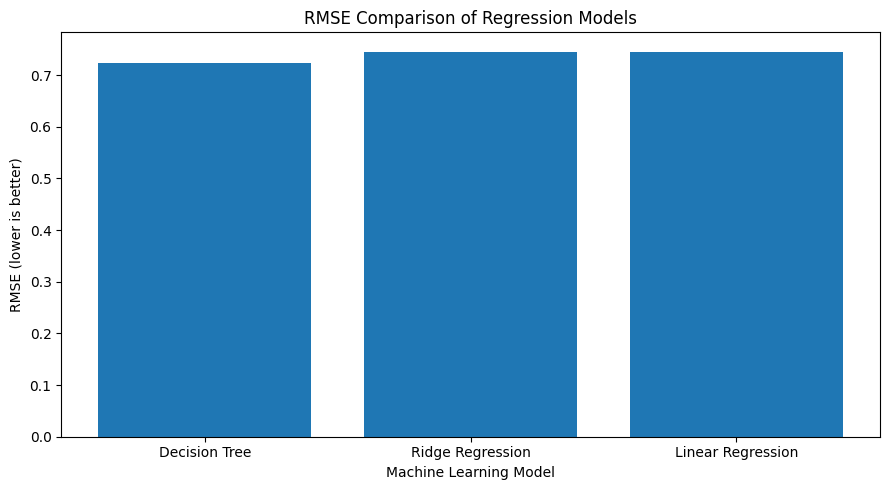

In [9]:

plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["RMSE"])

plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE (lower is better)")
plt.tight_layout()
plt.show()


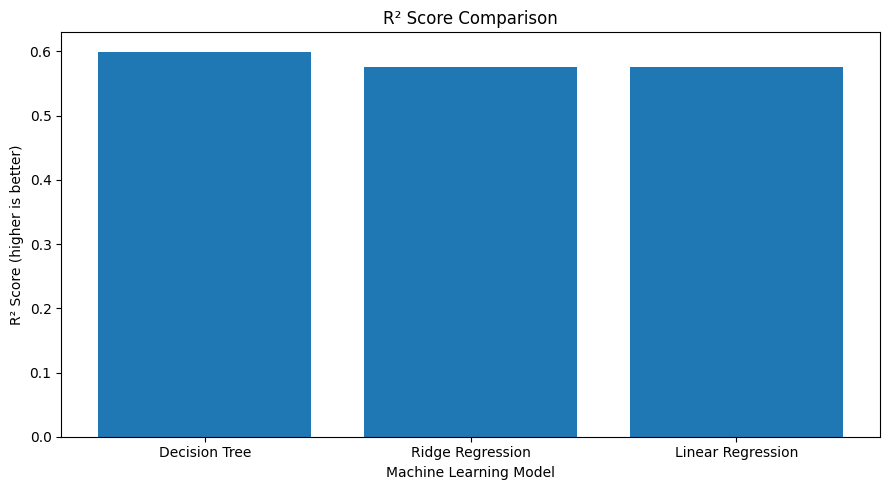

In [10]:

plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["R2 Score"])

plt.title("R² Score Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score (higher is better)")
plt.tight_layout()
plt.show()


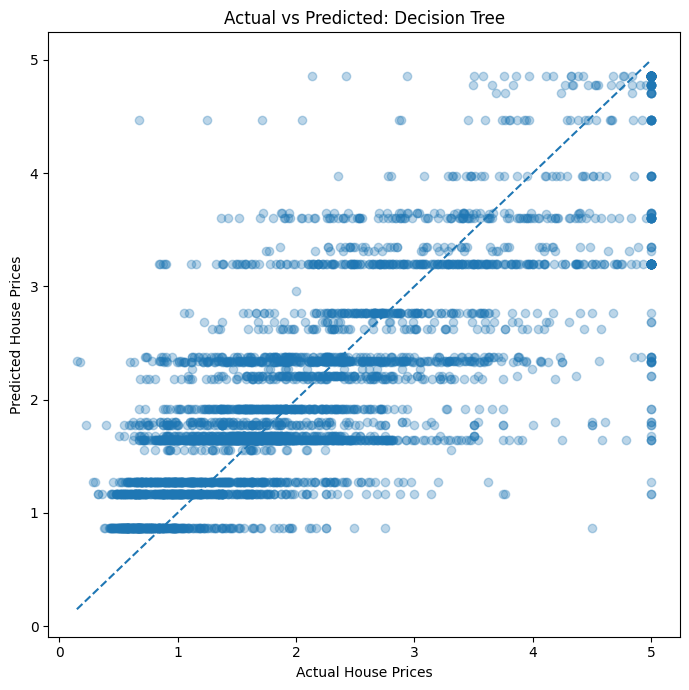

In [11]:

y_pred = best_model.predict(X_test_scaled)

plt.figure(figsize=(7, 7))

plt.scatter(y_test, y_pred, alpha=0.3)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.tight_layout()
plt.show()


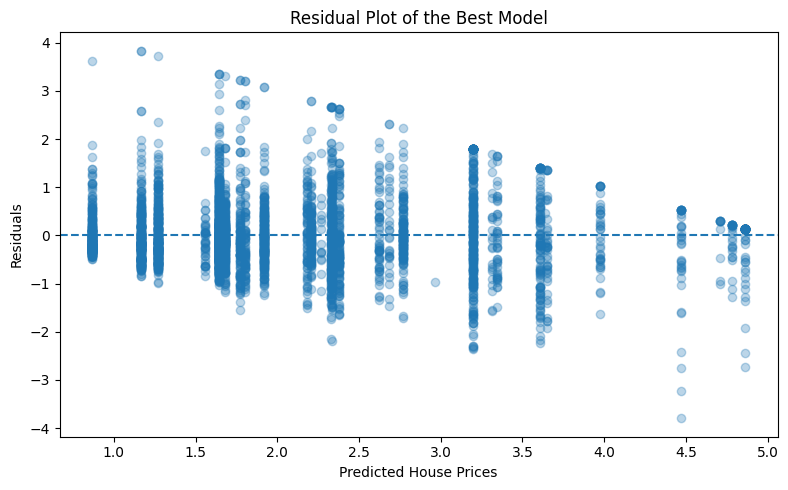

In [12]:

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot of the Best Model")
plt.tight_layout()
plt.show()


In [13]:

results_df.to_csv("model_performance_comparison.csv", index=False)

print("Model comparison table saved successfully!")


Model comparison table saved successfully!


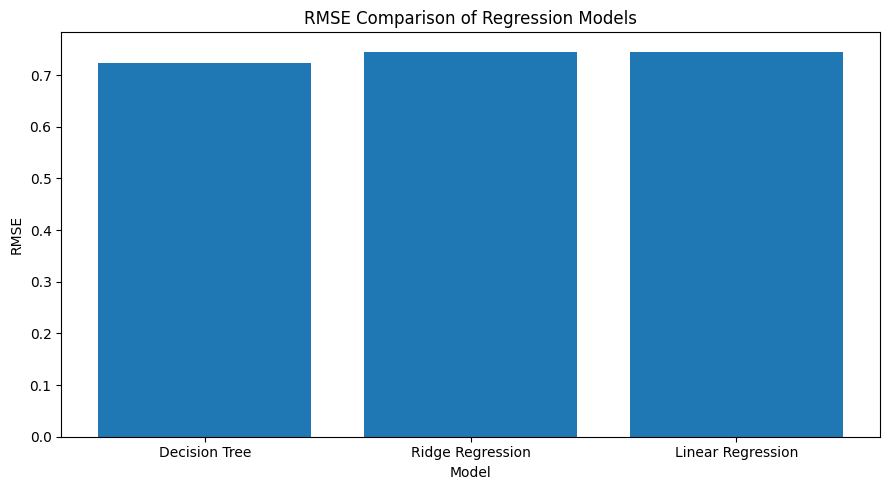

Comparison chart saved successfully!


In [14]:

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.tight_layout()

plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("Comparison chart saved successfully!")


In [15]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:

import joblib

joblib.dump(best_model, "best_house_price_model.pkl")
joblib.dump(scaler, "feature_scaler.pkl")

print("Best model and scaler saved successfully!")
print("Selected model:", best_model_name)


Best model and scaler saved successfully!
Selected model: Decision Tree


In [17]:

print("Selected model:", best_model_name)
print("Best model RMSE:", round(best_result["RMSE"], 4))
print("Best model MAE:", round(best_result["MAE"], 4))
print("Best model R2 score:", round(best_result["R2 Score"], 4))



Selected model: Decision Tree


NameError: name 'best_result' is not defined

In [18]:

print("Selected model:", best_model_name)
print("Best model RMSE:", round(best_result["RMSE"], 4))
print("Best model MAE:", round(best_result["MAE"], 4))
print("Best model R2 score:", round(best_result["R2 Score"], 4))


Selected model: Decision Tree


NameError: name 'best_result' is not defined

In [19]:

# Check whether the model results are available

try:
    results_df = results_df.sort_values(
        by="RMSE",
        ascending=True
    ).reset_index(drop=True)

    best_result = results_df.iloc[0]
    best_model_name = best_result["Model"]

    print("Selected model:", best_model_name)
    print("Best model RMSE:", round(best_result["RMSE"], 4))
    print("Best model MAE:", round(best_result["MAE"], 4))
    print("Best model R2 score:", round(best_result["R2 Score"], 4))

except NameError:
    print("Model results are not available.")
    print("Please run the model training and evaluation cell first.")


Selected model: Decision Tree
Best model RMSE: 0.7242
Best model MAE: 0.5223
Best model R2 score: 0.5997


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("R2 Score Comparison")
plt.xlabel("Model")
plt.ylabel("R2 Score (higher is better)")
plt.tight_layout()

plt.savefig("r2_comparison.png", dpi=300)
plt.show()

print("R2 comparison chart saved!")


In [ ]:

y_pred = best_model.predict(X_test_scaled)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.3)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()

plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()

print("Actual vs predicted chart saved!")


In [ ]:

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.tight_layout()

plt.savefig("residual_plot.png", dpi=300)
plt.show()

print("Residual plot saved!")


In [ ]:

import os

print("Files saved in:", os.getcwd())

for filename in [
    "r2_comparison.png",
    "actual_vs_predicted.png",
    "residual_plot.png"
]:
    print(filename, "—", "Found" if os.path.exists(filename) else "Missing")
